In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def draw3DRectangle(ax, x1, y1, z1, x2, y2, z2):
    # the Translate the datatwo sets of coordinates form the apposite diagonal points of a cuboid
    ax.plot([x1, x2], [y1, y1], [z1, z1], color='b') # | (up)
    ax.plot([x2, x2], [y1, y2], [z1, z1], color='b') # -->
    ax.plot([x2, x1], [y2, y2], [z1, z1], color='b') # | (down)
    ax.plot([x1, x1], [y2, y1], [z1, z1], color='b') # <--

    ax.plot([x1, x2], [y1, y1], [z2, z2], color='b') # | (up)
    ax.plot([x2, x2], [y1, y2], [z2, z2], color='b') # -->
    ax.plot([x2, x1], [y2, y2], [z2, z2], color='b') # | (down)
    ax.plot([x1, x1], [y2, y1], [z2, z2], color='b') # <--
    
    ax.plot([x1, x1], [y1, y1], [z1, z2], color='b') # | (up)
    ax.plot([x2, x2], [y2, y2], [z1, z2], color='b') # -->
    ax.plot([x1, x1], [y2, y2], [z1, z2], color='b') # | (down)
    ax.plot([x2, x2], [y1, y1], [z1, z2], color='b') # <--

In [3]:
def plot_field(field, draw_box=False):

    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')

    ax.scatter(field[:, 1], field[:, 2], field[:, 3], c=field[:, 0])

    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-1, 1)

    if draw_box:
        _, min_x, min_y, min_z = np.min(field, axis=0)
        _, max_x, max_y, max_z = np.max(field, axis=0)
        print(min_x, min_y, min_z, max_x, max_y, max_z)
        draw3DRectangle(ax, min_x, min_y, min_z, max_x, max_y, max_z)

    plt.autoscale(False)
    plt.show()

In [26]:
field = np.load("/workspace/Neo/relevancy_field_2.npy")
field.shape

(480, 640, 24, 4)

In [27]:
# Reduce dimensionality
reduce_factor = 4
reduced_field = field[np.arange(0, field.shape[0] - 1, reduce_factor), :, :, :]
reduced_field = reduced_field[:, np.arange(0, field.shape[1] - 1, reduce_factor), :]
reduced_field.shape

(120, 160, 24, 4)

In [192]:
reduced_field = reduced_field.reshape(-1, 4)

In [7]:
# ray = field[0, 0, :, :]
# ray[:, -1] = np.round(ray[:, -1], decimals=2)
# ray

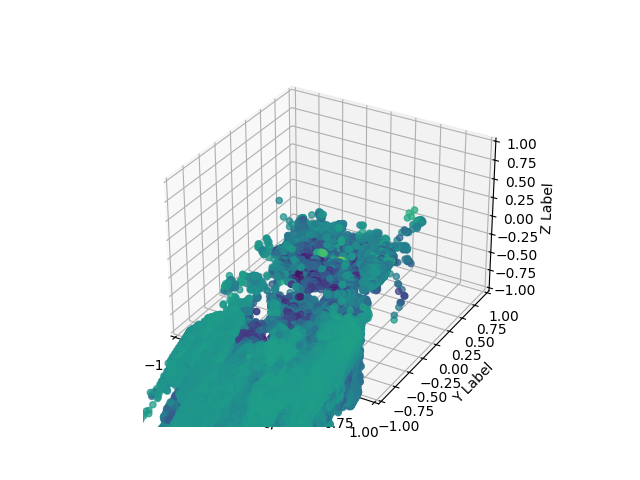

In [29]:
plot_field(reduced_field)

In [193]:
idxs = reduced_field[:, 0] > 0.6
high_rel_field = reduced_field[idxs]
high_rel_field.shape

(1083, 4)

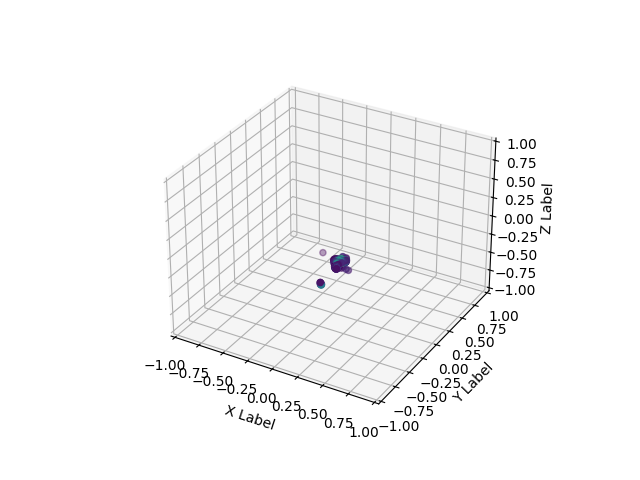

In [31]:
plot_field(high_rel_field)

In [201]:
from sklearn.cluster import DBSCAN
import numpy as np

db = DBSCAN(eps=0.05, min_samples=100).fit(high_rel_field)
labels = db.labels_
num_groups = len(np.unique(labels)) - 1

dbscan_fields = []
for i in range(num_groups):
    mask = np.where(labels == i, True, False)
    dbscan_fields.append(high_rel_field[mask])

mean_relevancies = []
for i in range(num_groups):
    mean_relevancy = np.mean(dbscan_fields[i], axis=0)[0]
    mean_relevancies.append(mean_relevancy)

0.04832714 -0.10812324 -0.3571911 0.14915991 0.00902158 -0.20582134


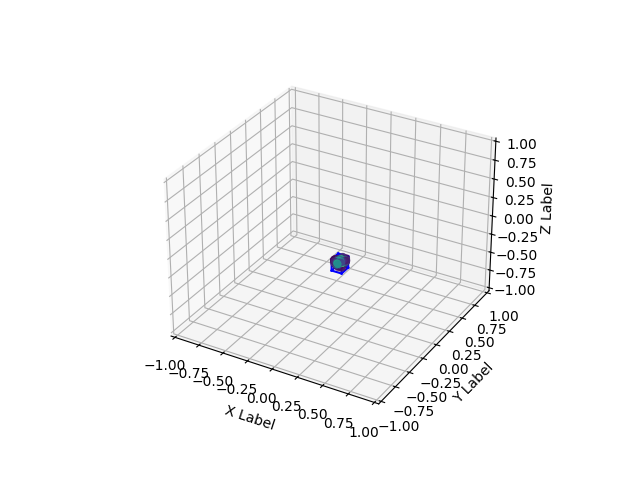

In [195]:
plot_field(dbscan_fields[0], draw_box=True)

[ 0.09067552 -0.04104689 -0.26787573]
[-37.19545799304297, -9.443959363809354, 119.04564214556835]
-0.06390837552425646 -0.06582690752398261 -0.08027697672751176 0.0296620222433921 0.05864210888308675 0.06329094101770388


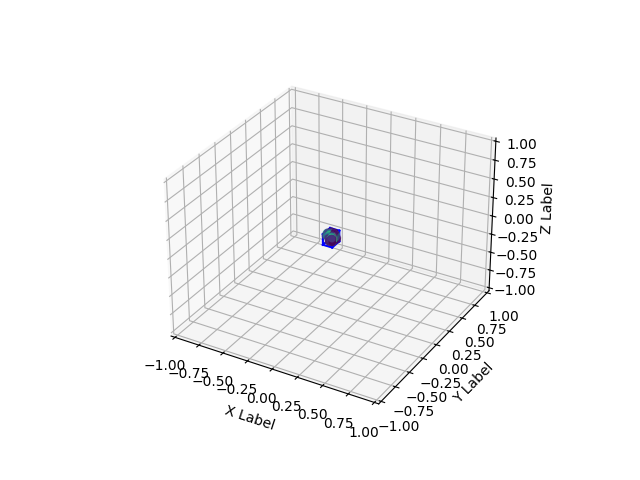

In [196]:
from scipy.spatial.transform import Rotation

data = dbscan_fields[0][:, 1:]
data = data.T
means = np.mean(data, axis=1)
print(means)
data = data - means[:, np.newaxis]
cov = np.cov(data)
eval, evec = np.linalg.eig(cov)
evec, _ = np.linalg.qr(evec)
R = Rotation.from_matrix(evec)
euler = list(R.as_euler('xyz', True))

print(euler)

aligned_coords = np.matmul(evec.T, data)

aligned_coords = np.concatenate([dbscan_fields[0][:, 0:1].T, aligned_coords], axis=0)

plot_field(aligned_coords.T, draw_box=True)

In [202]:
from scipy.spatial.transform import Rotation
import json

bboxes = {"bboxes":[]}
for i in range(num_groups):
    print(f"Group number: {i}")
    # group = dbscan_fields[i]

    data = dbscan_fields[i][:, 1:]
    data = data.T
    means = np.mean(data, axis=1)
    data -= means[:, np.newaxis]
    cov = np.cov(data)
    eval, evec = np.linalg.eig(cov)
    evec, _ = np.linalg.qr(evec)

    aligned_coords = np.matmul(evec.T, data)

    # aligned_coords = np.concatenate([dbscan_fields[0][:, 0:1].T, aligned_coords], axis=0)

    min_x, min_y, min_z = np.min(aligned_coords.T, axis=0).astype(float)
    max_x, max_y, max_z = np.max(aligned_coords.T, axis=0).astype(float)

    dimensions = [np.round(np.abs(max_x - min_x), decimals=2), np.round(np.abs(max_y - min_y), decimals=2), np.round(np.abs(max_z - min_z), decimals=2)]
    R = Rotation.from_matrix(evec)
    euler = list(R.as_euler('xyz', False))
    euler = [0.0, 0.0, -euler[2]]
    quaternion = list(R.as_quat(False))
    position = list(means.astype(float))

    print(dimensions)
    print(euler)
    print(quaternion)
    print(position)

    offset_position = [0.0, 0.0, 0.0]
    offset_euler = [0.0, 0.0, 0.0]

    bbox_data = {"idx": i, 
                 "data": {"dimensions": dimensions, 
                          "euler": euler, 
                          "quaternion": quaternion, 
                          "position": position, 
                          "is_reconfigured": False,
                          "offset_position": offset_position, 
                          "offset_euler": offset_euler
                          }}
    bboxes["bboxes"].append(bbox_data)

with open('/workspace/Neo/outputs/figurines/neo/2024-08-04_225712/bbox.json', 'w') as f:
# with open('bbox.json', 'w') as f:
    json.dump(bboxes, f, indent=2)

Group number: 0
[0.09, 0.12, 0.14]
[0.0, 0.0, -2.0777384155910945]
[-0.0939646344752922, -0.31349626765215005, 0.8007390634688061, 0.501704783584127]
[0.09067551791667938, -0.04104689136147499, -0.2678757309913635]
